# Notebook 4 (Route 11) - Understand, select, and compare Route 11 models

**Continue from Notebook 3 (Route 11).** Run its final export cell first, so `Route11_Development.csv` is beside this notebook. Loading the workbook, cleaning, and schedule matching are already done.

**Question:** can direction, timepoint, trip variant, scheduled hour, and weekday predict Route 11 arrival delay better than the timetable and simple historical medians?

**Scope:** provisional non-terminal arrivals at NE Walmart Supercenter (both directions) and Health Department (branch trips, both directions). Training uses the first 10 dates and validation the next 3. Final-test dates are not in the input file. Most days have two buses: 2111 on the main loop and 710 on the branch.

**Known in advance:** direction, timepoint, trip variant, scheduled hour, and weekday all come from the published schedule or calendar. Actual arrival, bus ID, IQR flags, and linkage status are **never** predictors.

Rerun top to bottom to reproduce every table and plot.

## 1. Load the development dataframe and show the full regression summary

`GROUPS` lists the five predictor concepts. Each categorical group (for example, all weekday indicators) is kept together during selection.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from itertools import combinations
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

arrivals = pd.read_csv("Route11_Development.csv", parse_dates=["service_date", "scheduled_arrival", "actual_arrival"],
                       dtype={"bus_id": "string", "stop_id": "string", "direction_id": "string"})
arrivals["service_pattern"] = arrivals["direction_id"] + " | " + arrivals["timepoint"] + " | " + arrivals["trip_variant"]
train = arrivals.loc[arrivals["split"].eq("train")].copy()
validation = arrivals.loc[arrivals["split"].eq("validation")].copy()

GROUPS = ["direction_id", "timepoint", "trip_variant", "scheduled_hour", "weekday"]
CATEGORICAL = ["direction_id", "timepoint", "trip_variant", "weekday", "service_pattern"]
TARGET = "delay_minutes"

assert train["service_date"].max() < validation["service_date"].min()
assert arrivals["service_date"].max() <= pd.Timestamp("2023-03-17")
assert not arrivals[[*GROUPS, TARGET, "service_date"]].isna().any().any()
assert arrivals["source_row"].is_unique
assert np.allclose(arrivals[TARGET], (arrivals["actual_arrival"] - arrivals["scheduled_arrival"]).dt.total_seconds() / 60)
print("Training:", len(train), "records on", train["service_date"].nunique(), "days")
print("Validation:", len(validation), "records on", validation["service_date"].nunique(), "days")
display(arrivals[["service_date", "bus_id", *GROUPS, TARGET]].head())

def design(training, evaluation, groups):
    if not groups:
        return (pd.DataFrame({"const": 1.0}, index=training.index),
                pd.DataFrame({"const": 1.0}, index=evaluation.index))
    a, b = training[list(groups)].copy(), evaluation[list(groups)].copy()
    categories = [g for g in groups if g in CATEGORICAL]
    for g in categories:
        levels = sorted(a[g].dropna().unique())
        a[g] = pd.Categorical(a[g], categories=levels)
        b[g] = pd.Categorical(b[g].where(b[g].isin(levels)), categories=levels)  # unseen label -> reference
    a = pd.get_dummies(a, columns=categories, drop_first=True, dtype=float)
    b = pd.get_dummies(b, columns=categories, drop_first=True, dtype=float)
    b = b.reindex(columns=a.columns, fill_value=0)
    return sm.add_constant(a.astype(float), has_constant="add"), sm.add_constant(b.astype(float), has_constant="add")

def fit_ols(training, groups):
    x, _ = design(training, training, groups)
    return sm.OLS(training[TARGET].astype(float), x).fit()

def ols_predict(training, evaluation, groups):
    fitted = fit_ols(training, groups)
    _, x = design(training, evaluation, groups)
    return fitted.predict(x).to_numpy()

full_model = fit_ols(train, GROUPS)
print(full_model.summary())

Training: 600 records on 10 days
Validation: 181 records on 3 days


,service_date,bus_id,direction_id,timepoint,trip_variant,scheduled_hour,weekday,delay_minutes
0,2023-03-01,2111,1,NE Walmart Supercenter,main_loop,5,Wednesday,0.166667
1,2023-03-01,2111,0,NE Walmart Supercenter,main_loop,6,Wednesday,4.433333
2,2023-03-01,2111,1,NE Walmart Supercenter,main_loop,6,Wednesday,1.400000
3,2023-03-01,2111,0,NE Walmart Supercenter,main_loop,7,Wednesday,4.033333
4,2023-03-01,2111,1,NE Walmart Supercenter,main_loop,7,Wednesday,2.550000


                            OLS Regression Results                            
Dep. Variable:          delay_minutes   R-squared:                       0.122
Model:                            OLS   Adj. R-squared:                  0.110
Method:                 Least Squares   F-statistic:                     10.29
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           1.60e-13
Time:                        13:58:26   Log-Likelihood:                -1365.6
No. Observations:                 600   AIC:                             2749.
Df Residuals:                     591   BIC:                             2789.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
const   

### How to read the summary

| Statistic | Meaning here | How to use it |
|---|---|---|
| Coefficient | Estimated difference in delay (minutes), holding the other inputs fixed | Association, not causation |
| Intercept | Predicted delay for the reference categories at hour 0 | A mathematical anchor only, since hour 0 is outside service |
| Std. error / 95% interval | Uncertainty under the model's assumptions | Wide interval = uncertain effect |
| P-value | Evidence against a zero coefficient under those assumptions | Not a measure of prediction quality |
| R² / adjusted R² | Training variance explained | Not an accuracy score on unseen dates |
| F-statistic | Joint test against an intercept-only model | A regression F-test, not a classification F1 |
| AIC / BIC | Training fit balanced against the number of parameters | Lower is better, but only for the same rows and target |

**Reference levels** (the omitted categories) are direction 0, Health Department, the branch, and Friday: the alphabetically first value of each category.

**Dependence caution:** stop visits on the same day are not independent. Below we also show **day-clustered** standard errors. With only 10 training days, treat both sets of p-values as rough.

In [2]:
clustered = full_model.get_robustcov_results(cov_type="cluster", groups=train["service_date"], use_correction=True)
uncertainty = pd.DataFrame({"coefficient_minutes": full_model.params,
                            "ordinary_p_value": full_model.pvalues,
                            "day_clustered_std_error": clustered.bse,
                            "day_clustered_p_value": clustered.pvalues}, index=full_model.params.index)
display(uncertainty.round(4))
print("Training design rank:", np.linalg.matrix_rank(full_model.model.exog), "/", full_model.model.exog.shape[1])

,coefficient_minutes,ordinary_p_value,day_clustered_std_error,day_clustered_p_value
const,0.2348,0.6172,0.5116,0.6571
scheduled_hour,0.0491,0.0903,0.0406,0.2577
direction_id_1,-0.8289,0.0000,0.2245,0.0050
timepoint_NE Walmart Supercenter,1.0461,0.0001,0.3262,0.0107
trip_variant_main_loop,0.3725,0.1183,0.3942,0.3694
weekday_Monday,-0.4580,0.1333,0.1361,0.0083
weekday_Thursday,0.9484,0.0022,0.8864,0.3125
weekday_Tuesday,-0.1388,0.6496,0.2186,0.5414
weekday_Wednesday,0.6156,0.0437,0.1314,0.0011


Training design rank: 9 / 9


## 2. The additive model misses an interaction

The regression above adds one effect for direction, one for timepoint, and one for variant. If those effects **combine** differently, for example "outbound + Walmart + main loop" being much later than the separate pieces suggest, the additive model cannot fit them. The table compares each combination's actual training median with the additive model's average prediction.

,records,median_delay,mean_delay,additive_model_mean_prediction,additive_gap_minutes
service_pattern,,,,,
0 | Health Department | health_dept_branch,80,-1.42,-0.23,1.04,-1.27
0 | NE Walmart Supercenter | health_dept_branch,76,1.01,1.65,2.06,-0.41
0 | NE Walmart Supercenter | main_loop,138,3.32,3.41,2.46,0.96
1 | Health Department | health_dept_branch,79,1.05,1.54,0.25,1.28
1 | NE Walmart Supercenter | health_dept_branch,78,1.42,1.68,1.29,0.40
1 | NE Walmart Supercenter | main_loop,149,0.45,0.72,1.61,-0.89


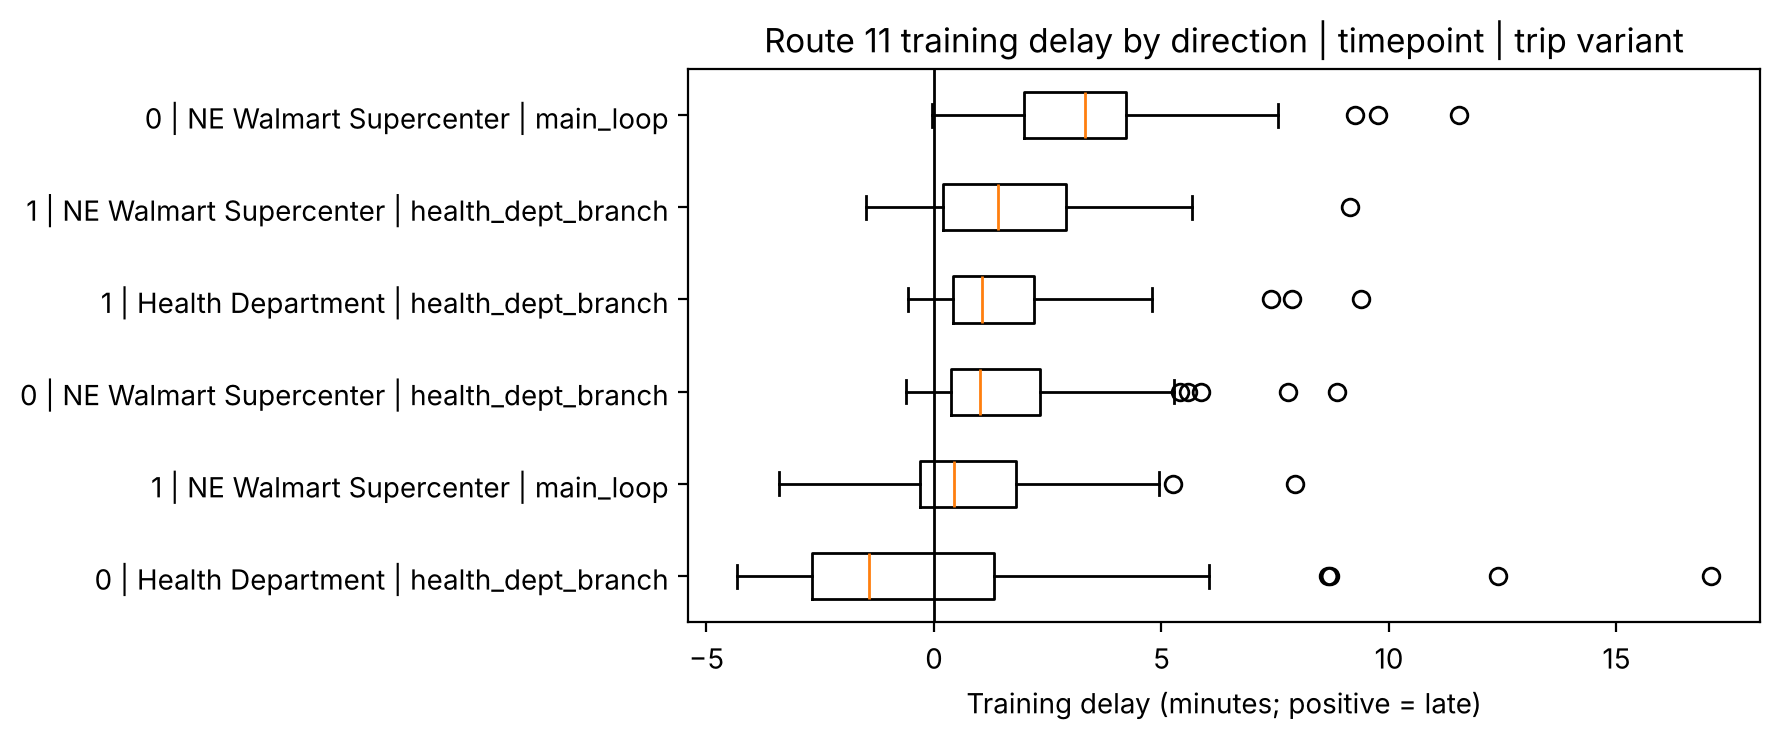

In [3]:
check = train.assign(additive_prediction=full_model.fittedvalues)
interaction_table = check.groupby("service_pattern").agg(
    records=(TARGET, "size"), median_delay=(TARGET, "median"), mean_delay=(TARGET, "mean"),
    additive_model_mean_prediction=("additive_prediction", "mean"))
interaction_table["additive_gap_minutes"] = interaction_table["mean_delay"] - interaction_table["additive_model_mean_prediction"]
display(interaction_table.round(2))

fig, ax = plt.subplots(figsize=(9, 3.8))
order = interaction_table.sort_values("median_delay").index
data_by_pattern = [train.loc[train["service_pattern"].eq(p), TARGET] for p in order]
try:
    ax.boxplot(data_by_pattern, orientation="horizontal", showfliers=True)   # matplotlib 3.10+
except TypeError:
    ax.boxplot(data_by_pattern, vert=False, showfliers=True)                 # older matplotlib
ax.set_yticks(range(1, len(order) + 1), order)
ax.axvline(0, color="black", linewidth=1)
ax.set(xlabel="Training delay (minutes; positive = late)", title="Route 11 training delay by direction | timepoint | trip variant")
fig.tight_layout()
plt.show()

**Read the plot:** each box is one combination of direction, timed stop, and variant. If the boxes sit at clearly different places that no simple "add three effects" rule can reproduce, we need an **interaction**. Below we add `service_pattern`, one category for each combination, as an alternative predictor group.

## 3. Compare all 32 subsets of the five predictor groups

With five groups there are 2⁵ = 32 subsets, including intercept-only. R², F, AIC, and BIC use all training records. `training_fold_MAE` uses expanding **training-date folds**: train on the first 4/6/8 dates and evaluate on the next 2. No validation dates are used. Picking the lowest fold error from this table and reporting it as an independent test would be optimistic.

In [4]:
training_dates = sorted(train["service_date"].unique())
folds = []
for end in [4, 6, 8]:
    a = train.loc[train["service_date"].isin(training_dates[:end])].copy()
    b = train.loc[train["service_date"].isin(training_dates[end:end + 2])].copy()
    assert a["service_date"].max() < b["service_date"].min()
    folds.append((a, b))

def fold_mae(groups):
    errors = []
    for a, b in folds:
        errors.extend(np.abs(b[TARGET].to_numpy() - ols_predict(a, b, groups)))
    return float(np.mean(errors))

subsets = [list(c) for size in range(len(GROUPS) + 1) for c in combinations(GROUPS, size)]
rows = []
for groups in subsets:
    fitted = fit_ols(train, groups)
    rows.append({"predictors": " + ".join(groups) or "Intercept only", "parameters": len(fitted.params),
                 "training_R2": fitted.rsquared, "adjusted_R2": fitted.rsquared_adj,
                 "AIC": fitted.aic, "BIC": fitted.bic, "training_fold_MAE_minutes": fold_mae(groups)})
for groups in [["service_pattern"], ["service_pattern", "scheduled_hour"],
               ["service_pattern", "weekday"], ["service_pattern", "scheduled_hour", "weekday"]]:
    fitted = fit_ols(train, groups)
    rows.append({"predictors": "INTERACTION: " + " + ".join(groups), "parameters": len(fitted.params),
                 "training_R2": fitted.rsquared, "adjusted_R2": fitted.rsquared_adj,
                 "AIC": fitted.aic, "BIC": fitted.bic, "training_fold_MAE_minutes": fold_mae(groups)})
subset_results = pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)
pd.set_option("display.max_colwidth", 80)
display(subset_results.round(3).head(15))
print("Lowest AIC:", subset_results.loc[subset_results["AIC"].idxmin(), "predictors"])
print("Lowest BIC:", subset_results.loc[subset_results["BIC"].idxmin(), "predictors"])
print("Lowest training-fold MAE:", subset_results.loc[subset_results["training_fold_MAE_minutes"].idxmin(), "predictors"])

,predictors,parameters,training_R2,adjusted_R2,AIC,BIC,training_fold_MAE_minutes
0,INTERACTION: service_pattern + weekday,10,0.262,0.251,2646.889,2690.858,1.792
1,INTERACTION: service_pattern + scheduled_hour + weekday,11,0.263,0.251,2648.362,2696.728,1.817
2,INTERACTION: service_pattern,6,0.221,0.214,2671.892,2698.274,1.683
3,INTERACTION: service_pattern + scheduled_hour,7,0.221,0.213,2673.459,2704.238,1.709
4,direction_id + timepoint + trip_variant + scheduled_hour + weekday,9,0.122,0.110,2749.290,2788.862,1.953
5,direction_id + timepoint + scheduled_hour + weekday,8,0.119,0.108,2749.768,2784.944,1.950
6,direction_id + timepoint + trip_variant + weekday,8,0.118,0.108,2750.204,2785.380,1.938
7,direction_id + timepoint + weekday,7,0.115,0.106,2750.250,2781.028,1.932
8,direction_id + trip_variant + scheduled_hour + weekday,8,0.100,0.089,2762.501,2797.676,1.946
9,direction_id + trip_variant + weekday,7,0.096,0.086,2763.244,2794.022,1.934


Lowest AIC: INTERACTION: service_pattern + weekday
Lowest BIC: INTERACTION: service_pattern + weekday
Lowest training-fold MAE: INTERACTION: service_pattern


## 4. Backward selection using AIC (additive groups)

Start with all five additive groups. At each step, try removing each group, and keep the removal that gives the lowest AIC, **but only if AIC goes down**. Stop when no removal helps. Each categorical group is removed as a whole.

In [5]:
def backward_aic(training, start_groups=GROUPS):
    kept = list(start_groups)
    path, candidates, step = [], [], 0
    while True:
        current = fit_ols(training, kept)
        path.append({"step": step, "predictors": " + ".join(kept) or "Intercept only", "AIC": current.aic, "BIC": current.bic})
        options = []
        for dropped in kept:
            trial = [g for g in kept if g != dropped]
            fitted = fit_ols(training, trial)
            options.append((fitted.aic, dropped, trial))
            candidates.append({"step": step, "remove": dropped, "remaining": " + ".join(trial) or "Intercept only", "AIC": fitted.aic})
        if not options:
            break
        best_aic, dropped, trial = min(options, key=lambda item: item[0])
        if best_aic >= current.aic - 1e-8:
            break
        kept, step = trial, step + 1
    return kept, pd.DataFrame(path), pd.DataFrame(candidates)

selected_groups, selection_path, removal_candidates = backward_aic(train)
display(removal_candidates.round(2))
display(selection_path.round(2))
print("Groups retained:", selected_groups)

,step,remove,remaining,AIC
0,0,direction_id,timepoint + trip_variant + scheduled_hour + weekday,2765.52
1,0,timepoint,direction_id + trip_variant + scheduled_hour + weekday,2762.50
2,0,trip_variant,direction_id + timepoint + scheduled_hour + weekday,2749.77
3,0,scheduled_hour,direction_id + timepoint + trip_variant + weekday,2750.20
4,0,weekday,direction_id + timepoint + trip_variant + scheduled_hour,2768.88


,step,predictors,AIC,BIC
0,0,direction_id + timepoint + trip_variant + scheduled_hour + weekday,2749.29,2788.86


Groups retained: ['direction_id', 'timepoint', 'trip_variant', 'scheduled_hour', 'weekday']


## 5. Compare complete procedures, including a random forest

Every procedure is scored on the **same** training-date folds and rows:

| Procedure | What it does |
| --- | --- |
| Published schedule | Predicts 0 minutes of delay |
| Historical median | One overall training median |
| Group median | Training median for each direction / timepoint / variant |
| Full additive regression | All five groups, no interaction |
| Backward AIC regression | Backward selection **redone inside each fold** |
| Interaction regression | `service_pattern` + scheduled hour + weekday |
| Random forest | 300 trees, depth 4, ≥10 rows per leaf, fixed in advance (no tuning on validation) |

The forest can learn interactions and non-linear hour effects on its own. **The procedure with the lowest pooled fold MAE is chosen before looking at validation.**

In [6]:
INTERACTION_GROUPS = ["service_pattern", "scheduled_hour", "weekday"]
PATTERN_KEYS = ["direction_id", "timepoint", "trip_variant"]

def forest():
    encoder = ColumnTransformer([
        ("categories", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["direction_id", "timepoint", "trip_variant", "weekday"]),
        ("hour", "passthrough", ["scheduled_hour"])])
    return Pipeline([("encode", encoder), ("model", RandomForestRegressor(
        n_estimators=300, max_depth=4, min_samples_leaf=10, random_state=42, n_jobs=1))])

def predict_procedure(name, training, evaluation):
    if name == "Published schedule":
        return np.zeros(len(evaluation)), "none"
    if name == "Historical median":
        return np.repeat(training[TARGET].median(), len(evaluation)), "none"
    if name == "Group median":
        lookup = training.groupby(PATTERN_KEYS)[TARGET].median().rename("m")
        joined = evaluation[PATTERN_KEYS].merge(lookup, left_on=PATTERN_KEYS, right_index=True, how="left")
        return joined["m"].fillna(training[TARGET].median()).to_numpy(), ", ".join(PATTERN_KEYS)
    if name == "Full additive regression":
        return ols_predict(training, evaluation, GROUPS), ", ".join(GROUPS)
    if name == "Backward AIC regression":
        groups, _, _ = backward_aic(training)
        return ols_predict(training, evaluation, groups), ", ".join(groups) or "intercept"
    if name == "Interaction regression":
        return ols_predict(training, evaluation, INTERACTION_GROUPS), ", ".join(INTERACTION_GROUPS)
    fitted = forest().fit(training[GROUPS], training[TARGET])
    return fitted.predict(evaluation[GROUPS]), ", ".join(GROUPS)

METHODS = ["Published schedule", "Historical median", "Group median", "Full additive regression",
           "Backward AIC regression", "Interaction regression", "Random forest"]
fold_scores, fold_predictions = [], []
for fold_number, (a, b) in enumerate(folds, start=1):
    for name in METHODS:
        predicted, used = predict_procedure(name, a, b)
        errors = b[TARGET].to_numpy() - predicted
        fold_scores.append({"fold": fold_number, "method": name, "training_rows": len(a), "evaluation_rows": len(b),
                            "predictors": used, "MAE_minutes": np.abs(errors).mean()})
        for row_id, error in zip(b["source_row"], errors):
            fold_predictions.append({"source_row": row_id, "method": name, "absolute_error": abs(error), "squared_error": error ** 2})
fold_scores = pd.DataFrame(fold_scores)
oof = pd.DataFrame(fold_predictions)
procedure_scores = oof.groupby("method").agg(records=("absolute_error", "size"), MAE_minutes=("absolute_error", "mean"),
                                             MSE=("squared_error", "mean"))
procedure_scores["RMSE_minutes"] = np.sqrt(procedure_scores.pop("MSE"))
procedure_scores = procedure_scores.sort_values("MAE_minutes")
chosen_procedure = procedure_scores.index[0]
display(fold_scores.pivot(index="method", columns="fold", values="MAE_minutes").round(3))
display(procedure_scores.round(4))
print("Procedure chosen using training folds only:", chosen_procedure)

fold,1,2,3
method,,,
Backward AIC regression,1.835,2.010,2.004
Full additive regression,1.833,2.026,1.999
Group median,1.649,1.175,1.742
Historical median,1.975,1.605,1.928
Interaction regression,1.702,1.894,1.855
Published schedule,2.114,1.820,2.122
Random forest,1.612,1.828,1.886


,records,MAE_minutes,RMSE_minutes
method,,,
Group median,364,1.5210,1.9805
Random forest,364,1.7756,2.2553
Interaction regression,364,1.8173,2.2913
Historical median,364,1.8351,2.3595
Backward AIC regression,364,1.9500,2.4902
Full additive regression,364,1.9529,2.4947
Published schedule,364,2.0181,2.6922


Procedure chosen using training folds only: Group median


## 6. Refit, report validation errors, and convert delay to arrival time

The training-fold choice is fixed **before** reading validation outcomes. Each procedure is refit on all training rows and scored on the same validation rows. All methods are shown to explain the experiment, but **do not switch to another method just because it wins this table.** These validation dates were already inspected in Notebook 3, so this is an exploratory replication, not a fresh test.

**Predicted arrival = scheduled arrival + predicted delay.** MAE is in minutes, not a percentage accuracy.

,method,chosen_by_training_folds,MAE_minutes,RMSE_minutes,validation_R2
0,Published schedule,False,1.6285,2.1570,-0.2476
1,Historical median,False,1.4811,1.9459,-0.0153
2,Group median,True,1.3390,1.6823,0.2411
3,Full additive regression,False,1.7234,2.1452,-0.2339
4,Backward AIC regression,False,1.7234,2.1452,-0.2339
5,Interaction regression,False,1.6729,2.0298,-0.1048
6,Random forest,False,1.5613,1.8826,0.0496


,service_date,service_pattern,scheduled_arrival,actual_arrival,predicted_arrival,absolute_error_minutes
600,2023-03-15,1 | NE Walmart Supercenter | main_loop,2023-03-15 05:40:00,2023-03-15 05:40:39,2023-03-15 05:40:27,0.20
601,2023-03-15,0 | NE Walmart Supercenter | main_loop,2023-03-15 06:07:00,2023-03-15 06:11:05,2023-03-15 06:10:19,0.77
602,2023-03-15,1 | NE Walmart Supercenter | main_loop,2023-03-15 06:40:00,2023-03-15 06:43:08,2023-03-15 06:40:27,2.68
603,2023-03-15,0 | NE Walmart Supercenter | main_loop,2023-03-15 07:07:00,2023-03-15 07:08:57,2023-03-15 07:10:19,1.37
604,2023-03-15,1 | NE Walmart Supercenter | main_loop,2023-03-15 07:40:00,2023-03-15 07:41:17,2023-03-15 07:40:27,0.83
605,2023-03-15,0 | NE Walmart Supercenter | main_loop,2023-03-15 08:07:00,2023-03-15 08:12:42,2023-03-15 08:10:19,2.38
606,2023-03-15,1 | NE Walmart Supercenter | main_loop,2023-03-15 08:40:00,2023-03-15 08:39:33,2023-03-15 08:40:27,0.90
607,2023-03-15,0 | NE Walmart Supercenter | main_loop,2023-03-15 09:07:00,2023-03-15 09:08:21,2023-03-15 09:10:19,1.97


,size,MAE_minutes
service_date,,
2023-03-15,61,1.377
2023-03-16,61,1.336
2023-03-17,59,1.303


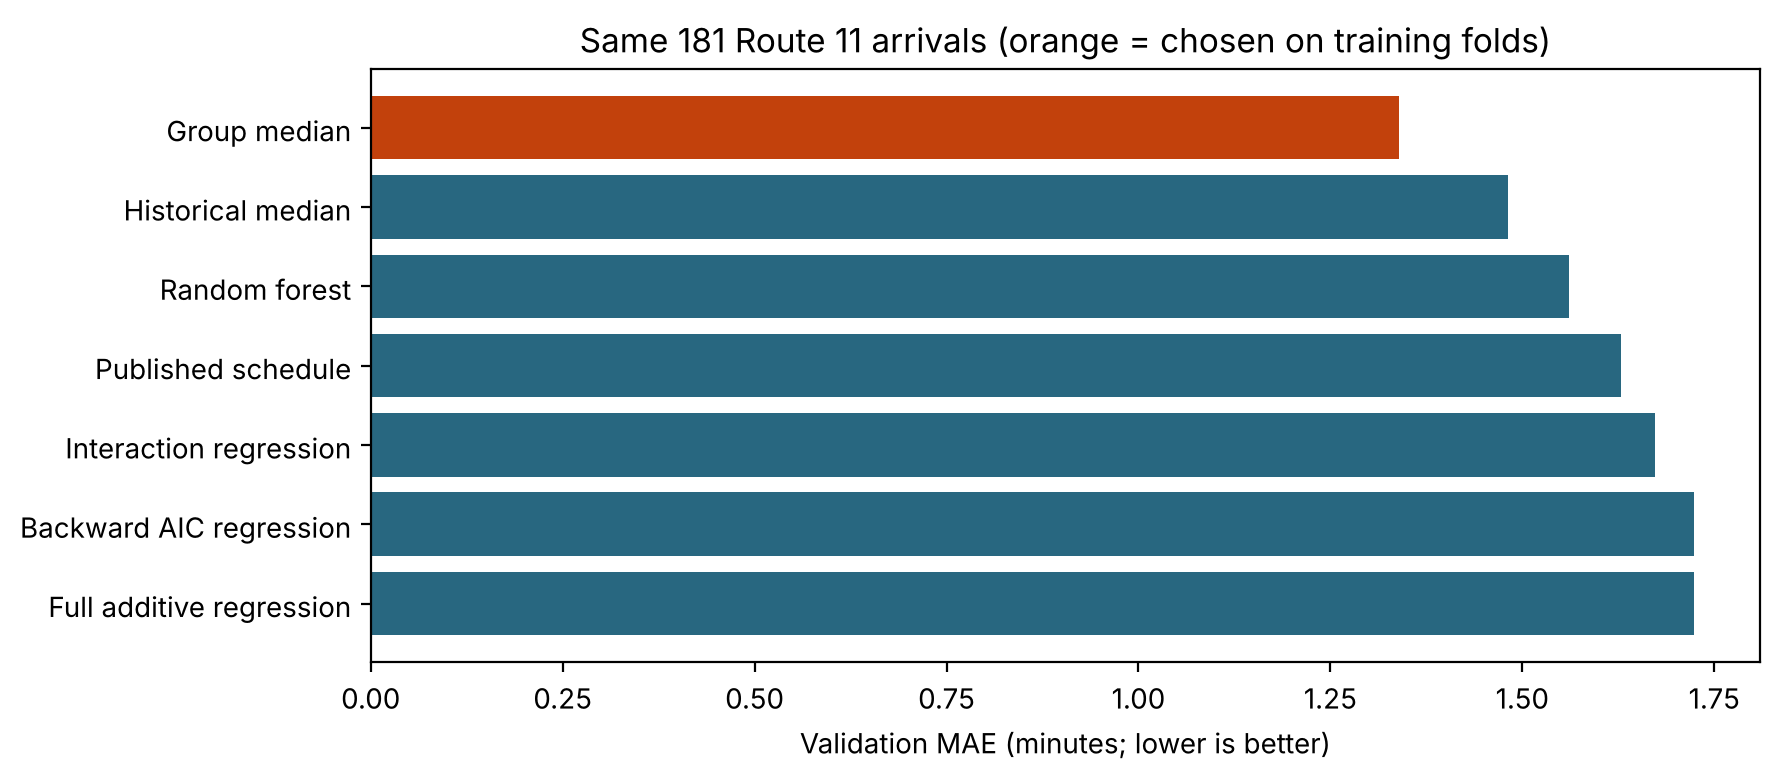

In [7]:
validation_rows = []
validation_predictions = validation[["source_row", "service_date", "bus_id", "service_pattern", "scheduled_hour",
                                     "scheduled_arrival", "actual_arrival", TARGET]].copy()
for name in METHODS:
    predicted, used = predict_procedure(name, train, validation)
    validation_predictions[name] = predicted
    validation_rows.append({"method": name, "chosen_by_training_folds": name == chosen_procedure,
                            "MAE_minutes": mean_absolute_error(validation[TARGET], predicted),
                            "RMSE_minutes": np.sqrt(mean_squared_error(validation[TARGET], predicted)),
                            "validation_R2": r2_score(validation[TARGET], predicted)})
validation_results = pd.DataFrame(validation_rows)
display(validation_results.round(4))

validation_predictions["predicted_arrival"] = (validation_predictions["scheduled_arrival"]
                                               + pd.to_timedelta(validation_predictions[chosen_procedure], unit="min")).dt.round("s")
validation_predictions["absolute_error_minutes"] = (validation_predictions[chosen_procedure] - validation[TARGET].to_numpy()).abs()
display(validation_predictions[["service_date", "service_pattern", "scheduled_arrival", "actual_arrival",
                                "predicted_arrival", "absolute_error_minutes"]].head(8).round({"absolute_error_minutes": 2}))
display(validation_predictions.groupby("service_date")["absolute_error_minutes"].agg(["size", "mean"])
        .rename(columns={"mean": "MAE_minutes"}).round(3))

fig, ax = plt.subplots(figsize=(9, 4))
plot = validation_results.sort_values("MAE_minutes", ascending=False)
colors = ["#c2410c" if c else "#286780" for c in plot["chosen_by_training_folds"]]
ax.barh(plot["method"], plot["MAE_minutes"], color=colors)
ax.set(xlabel="Validation MAE (minutes; lower is better)",
       title=f"Same {len(validation)} Route 11 arrivals (orange = chosen on training folds)")
fig.tight_layout()
plt.show()

In [8]:
by_method = validation_results.set_index("method")
fold_by_method = procedure_scores["MAE_minutes"]
schedule_mae = by_method.loc["Published schedule", "MAE_minutes"]
print(f"{'method':28s} {'fold MAE':>9s} {'valid MAE':>10s} {'error vs schedule':>18s}")
for name in METHODS:
    v = by_method.loc[name, "MAE_minutes"]
    print(f"{name:28s} {fold_by_method[name]:9.3f} {v:10.3f} {100 * (v / schedule_mae - 1):+17.1f}%")
print()
print("Chosen on training folds:", chosen_procedure)
print("Lowest validation MAE:  ", by_method["MAE_minutes"].idxmin())

interaction_fit = fit_ols(train, INTERACTION_GROUPS)
print("\nInteraction regression - coefficients (minutes):")
display(interaction_fit.params.round(3).to_frame("coefficient"))

method                        fold MAE  valid MAE  error vs schedule
Published schedule               2.018      1.628              +0.0%
Historical median                1.835      1.481              -9.0%
Group median                     1.521      1.339             -17.8%
Full additive regression         1.953      1.723              +5.8%
Backward AIC regression          1.950      1.723              +5.8%
Interaction regression           1.817      1.673              +2.7%
Random forest                    1.776      1.561              -4.1%

Chosen on training folds: Group median
Lowest validation MAE:   Group median

Interaction regression - coefficients (minutes):


,coefficient
const,-0.662
scheduled_hour,0.019
service_pattern_0 | NE Walmart Supercenter | health_dept_branch,1.904
service_pattern_0 | NE Walmart Supercenter | main_loop,3.646
service_pattern_1 | Health Department | health_dept_branch,1.753
service_pattern_1 | NE Walmart Supercenter | health_dept_branch,1.910
service_pattern_1 | NE Walmart Supercenter | main_loop,0.954
weekday_Monday,-0.462
weekday_Thursday,0.949
weekday_Tuesday,-0.140


## 7. Results explained - answers for the research group

*Numbers come from the saved run. Rerun top to bottom if any rule changes.*

### What did the regression statistics tell us?
The full additive model explains only **12.2%** of training delay variation (adjusted R² **0.110**; F = 10.29, p = 1.6e-13). Route 7's model explained 41.8%, so these inputs predict Route 11 delays much less well. The clearest effects are:
- **Inbound trips are about 0.83 minutes less late** than outbound trips (day-clustered p = 0.005).
- **Walmart arrivals are about 1.05 minutes later** than Health Department arrivals (day-clustered p = 0.011).

Thursday's +0.95 minutes looks significant under ordinary errors (p = 0.002) but not under day-clustered errors (p = 0.31). It rests on two training Thursdays, so treat it as a day-specific pattern, not a weekday effect.

### Is there an interaction?
Yes. The additive model misses each direction/timepoint/variant combination by **0.4-1.3 minutes on average**. Its worst miss is outbound Health Department on the branch: the actual training mean is −0.23 minutes (slightly early), but the model predicts +1.04. Replacing the three separate groups with one `service_pattern` category lowers AIC from 2749 to 2647 and doubles training R² (0.12 → 0.26).

### Which features did backward selection keep?
**All five.** Removing any group raises AIC. AIC measures training fit, though, and the training-date folds disagree: adding weekday to `service_pattern` **raises** fold MAE from 1.68 to 1.79 minutes. Weekday helps describe the training days but does not carry over to new days.

### Which procedure is best?
| | Fold MAE | Validation MAE | vs schedule |
| --- | --- | --- | --- |
| **Group median** (chosen) | **1.52** | **1.34** | **−17.8%** |
| Random forest | 1.78 | 1.56 | −4.1% |
| Historical median | 1.84 | 1.48 | −9.0% |
| Interaction regression | 1.82 | 1.67 | +2.7% (worse) |
| Additive regression | 1.95 | 1.72 | +5.8% (worse) |
| Published schedule | 2.02 | 1.63 | - |

Unlike Route 7, **the training-fold choice and the validation winner agree.** That makes the Route 11 conclusion more stable, although validation is still only three days.

### Why does a lookup table beat a regression that uses the same information?
The group median is essentially the interaction regression **without hour and weekday**, using a **median instead of a mean**.
1. **Skew:** delays have a long late tail (residual skew 0.96). One example is a run of branch arrivals 7-17 minutes late on March 2. Regression fits averages, which get pulled toward those tails. MAE rewards the median.
2. **Noise from weak predictors:** hour and weekday add parameters estimated from few days and do not improve later dates.

### What to take away
- A **pattern-specific historical median** is the strongest Route 11 baseline so far: about 0.3 minutes (17-18 seconds) better per arrival than the timetable.
- Flexible models (forest, regression) did **not** beat it. Extra complexity needs evidence.
- **Next experiment to consider:** a *median (quantile) regression* with `service_pattern` (+ hour). It keeps the median's resistance to skew and can still use hour. Decide on it **before** the final test, not because of the final test.
- Findings remain limited by provisional schedule links, the bus-710/branch confound, the Walmart 30-minute ambiguity, and a validation set already inspected.

## 8. Comparing Route 11 with Route 7

| | Route 7 | Route 11 |
| --- | --- | --- |
| Defensible development labels | 304 (232 train / 72 validation) | 781 (600 train / 181 validation) |
| Timed middle stops modeled | Health Department | Walmart (both directions) + Health Department (branch) |
| Buses per day | 1 | Usually 2 (main loop + branch) |
| Published-schedule validation MAE | 2.71 min | 1.63 min |
| Best simple baseline on validation | Overall median, 1.63 min (−39.8%) | Group median, 1.34 min (−17.8%); overall median 1.48 min (−9.0%) |
| Training-fold choice | Random forest (lost on validation) | Group median (also best on validation) |

**Questions for the group:**

1. **Is a pooled two-route model worth trying?** Both routes share the Downtown and Eastwood terminals and the Health Department stop, but their schedules, patterns, and delay levels differ. Start with separate models, and add `route` as a category only as an explicit experiment.
2. **Should Route 7 also try a group median?** Route 7 has a single timed middle stop and one pattern, so its "group median" is just a median per direction. It is worth checking whether that beats Route 7's overall median.
3. **Can we separate the branch effect from bus 710?** Only if another bus ever runs the branch. Check the final-test dates' bus assignments **without** looking at their delays.
4. **What should the frozen final-test procedure be?** Decide now, in writing: the label rules from Notebook 3, the chosen procedure, and a single scoring of March 20-23.
5. **Would previous-timepoint delay help?** For example, a bus's delay at Walmart on the way to Health Department. It is known before the next arrival, but it requires a schedule link that doesn't depend on later observations.

## Optional: save the result tables

Uncomment to save new files beside this notebook. `Route11_Development.csv` is not changed.

In [9]:
# subset_results.to_csv("Route11_Feature_Subsets.csv", index=False)
# selection_path.to_csv("Route11_Backward_AIC_Path.csv", index=False)
# procedure_scores.to_csv("Route11_Training_Fold_Comparison.csv")
# validation_results.to_csv("Route11_Feature_Validation.csv", index=False)